# Introduction

This interactive notebook shows several examples for using the rxn_rdf_converter package to convert ord-data to linked data in JSON-LDs.
The files and directories are organized by follow: 

1. **ord-data-example**: three example ord-data sets.  
2. **MDS_Onto.owl**: the latest version MDS-Onto file can be found in the parent directory. 
3. **jsonld-examples**: the JSON-LD files will be generated in this directory.  

We use PyOxiGraph to store and performed queries upon the JSON-LDs generated.
There are several example SPARQL queries on the JSON-LDs generated. 
Lastly, we have one last example for visualization of the chemical reaction in the JSON-LD generated. 

# Part 1: Converting from ORD to JSON-LD

### Example 1: Convert a subset of reactions from one ord-data set to JSON-LD

Note: This script converts 10 random reactions from one of the test ORD datasets to JSON-LD files. If the user wishes to use this code for converting part of their own dataset, they need to change the following things:

1\. The path to their ORD dataset (dataset_path)  
2\. The output and log directories (output_dir and log_dir)  
3\. (Optional) The number of reactions to convert (count)  
4\. (Optional) If they want to generate different random reactions every time they run the cell, they need to remove the line defining the seed (seed = 42) and change the line that determines the random indices to the second option provided below

Note: The JSON-LDs created as a result of running this cell with a seed of 42 are the JSON-LDs in the package's jsonld-examples folder.

In [1]:
from pathlib import Path
import sys
from ord_schema.proto import dataset_pb2
import random
from rxn_rdf_converter import dataset_processor
from pathlib import Path
import gzip

notebook_dir = Path.cwd()
dataset_path = notebook_dir.parent / "ord-data-examples" / "ord_dataset-00005539a1e04c809a9a78647bea649c.pb.gz"

# Use the ontology version in the package
owl_onto_path = notebook_dir.parent / 'MDS_Onto.owl'
output_dir = notebook_dir.parent / 'jsonld-examples' # Used to convert 10 random reactions
log_dir = notebook_dir.parent / 'logs'

# Replace this with the number of reaction JSON-LDs you want to create
count = 10

# Keep the seed the same for reproducibility; remove the line if you want
# to generate different reaction JSON-LDs every time
seed = 42

# Creates the dataset processor
processor = dataset_processor.DatasetProcessor(
    dataset_pb=dataset_pb2,
    dataset_file_path=str(dataset_path),
    owl_onto_file_path=str(owl_onto_path),
    output_directory=str(output_dir),
    error_log_directory=str(log_dir),
    fmt="json-ld",
)

# Ensures that there are enough reactions in the dataset to generate the number you requested
total = len(processor.dataset.reactions)
if total < count:
    raise ValueError(f"Requested {count} reactions, but dataset has {total}.")

# Delete this line if you don't want to use a seed for generating random reactions
indices = random.Random(seed).sample(range(total), count)

# Use this line instead if you don't want to use a seed for generating random reactions
#indices = random.sample(range(total), count)

reported_exports = []
errors = []

for index in indices:

    pb_rxn = processor.dataset.reactions[index]

    try:
        result = (
            dataset_processor.ReactionKG(pb_rxn, fmt=processor.fmt)
            .generate_reaction()
            .generate_instances(processor.owl_onto)
            .generate_data_graph(
                processor.dataset_id,
                str(output_dir),
            )
        )

        if result is None:
            errors.append(
                (pb_rxn.reaction_id, "generate_data_graph returned None")
            )
        else:
            reported_exports.append(pb_rxn.reaction_id)
            print("Reported export:", pb_rxn.reaction_id)

    except Exception as exc:
        errors.append((pb_rxn.reaction_id, str(exc)))

# Removes the empty test folder created by the dataset processor's constructor
unused_folder = Path(processor.output_dir)
if unused_folder.is_dir() and not any(unused_folder.iterdir()):
    unused_folder.rmdir()

print(f"\nSelected: {count}")
print(f"Reported exports: {len(reported_exports)}")
print(f"Caught errors: {len(errors)}")
print("Output directory:", output_dir)

# Prints any errors that might have occurred when converting to JSON-LD
for reaction_id, message in errors:
    print(reaction_id, message)

INFO 2026-11-20 20:59:14,895 dataset_processor.py:78: DatasetProcessor initiated for dataset: 00005539a1e04c809a9a78647bea649c
INFO 2026-11-20 20:59:14,897 dataset_processor.py:79: Dataset file: /mnt/vstor/CSE_MSE_RXF131/cradle-members/mds3/qdt/git/rxn-rdf-converter/ord-data-examples/ord_dataset-00005539a1e04c809a9a78647bea649c.pb.gz
INFO 2026-11-20 20:59:14,899 dataset_processor.py:80: Output Directory: /mnt/vstor/CSE_MSE_RXF131/cradle-members/mds3/qdt/git/rxn-rdf-converter/jsonld-examples/ord-data-examples
INFO 2026-11-20 20:59:14,900 dataset_processor.py:81: Format: json-ld


attempting to load_message(/mnt/vstor/CSE_MSE_RXF131/cradle-members/mds3/qdt/git/rxn-rdf-converter/ord-data-examples/ord_dataset-00005539a1e04c809a9a78647bea649c.pb.gz, dataset_pb.DataSet_


* Owlready2 * WARNING: ObjectProperty https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#hasFileFormat belongs to more than one entity types: [owl.DatatypeProperty, owl.ObjectProperty]; I'm trying to fix it...
* Owlready2 * WARNING: ObjectProperty https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#hasMinimumLatitude belongs to more than one entity types: [owl.DatatypeProperty, owl.ObjectProperty]; I'm trying to fix it...
* Owlready2 * WARNING: ObjectProperty https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#hasMaximumLatitude belongs to more than one entity types: [owl.DatatypeProperty, owl.ObjectProperty]; I'm trying to fix it...
* Owlready2 * WARNING: ObjectProperty https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#hasMinimumLongitude belongs to more than one entity types: [owl.DatatypeProperty, owl.ObjectProperty]; I'm trying to fix it...
* Owlready2 * WARNING: ObjectProperty https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#hasMaximumLongi

Reported export: ord-7d6438f5772442a8addd4f9357140a8b
Reported export: ord-63adda83987840e4a77972b9a1ad7b3d
Reported export: ord-f766bf8ef3f8450eb6d323fd10519896
Reported export: ord-69231428717b458492fb802f1da5509b
Reported export: ord-019ad9f92b5c40ecbf5416e8a6461063
Reported export: ord-f1632d43480c447bab6a25aa93c74396


[20:59:15] WARNING: Proton(s) added/removed

[20:59:15] WARNING: Proton(s) added/removed

[20:59:15] WARNING: Proton(s) added/removed



Reported export: ord-10a49d7456a04dcab0790ed1d012aba2
Reported export: ord-b3b59923db4e4673a6bcde3d5a9c7727
Reported export: ord-411cbd769b2f48f9a0808a7d2919db15
Reported export: ord-805e4c9d19604f5ca8a6f376906a62c5

Selected: 10
Reported exports: 10
Caught errors: 0
Output directory: /mnt/vstor/CSE_MSE_RXF131/cradle-members/mds3/qdt/git/rxn-rdf-converter/jsonld-examples


[20:59:15] WARNING: Proton(s) added/removed



### Example 2: Convert multiple datasets of reactions from ORD to JSON-LD

Note: This script converts all reactions in the three example ord-data sets to JSON-LD files. If the user wishes to use this code for converting their own dataset, they need to change the following things:

1\. The path to their ORD dataset (dataset_path)  
2\. The output and log directories (output_dir and log_dir)  

Note: The conversion may produce a long output; enabling output scrolling is suggested.

In [2]:
from pathlib import Path
import sys
import random
from ord_schema.proto import dataset_pb2
from rxn_rdf_converter import dataset_processor
from pathlib import Path
import gzip

notebook_dir = Path.cwd()

example_folder = notebook_dir.parent / "ord-data-examples" 
data_list = [
    file 
    for file in example_folder.rglob("*.pb.gz")
]

# Use the ontology version in the package
owl_onto_path = notebook_dir.parent / 'MDS_Onto.owl'
output_dir = notebook_dir.parent / 'jsonld-examples' # Used to convert 10 random reactions
log_dir = notebook_dir.parent / 'logs'

capture_path = log_dir / "notebook-conversion-output.log"

# Creates the dataset processor
for data in data_list: 
    processor = dataset_processor.DatasetProcessor(
        dataset_pb=dataset_pb2,
        dataset_file_path=str(data),
        owl_onto_file_path=str(owl_onto_path),
        output_directory=str(output_dir),
        error_log_directory=str(log_dir),
        fmt="json-ld",
    )

count = 15 
seed = 42

indices = random.Random(seed).sample(range(total), count)
total = len(indices)
print(f"Converting all {total} reactions")

reported_exports = []
errors = []

for index in indices:

    pb_rxn = processor.dataset.reactions[index]

    try:
        result = (
            dataset_processor.ReactionKG(pb_rxn, fmt=processor.fmt)
            .generate_reaction()
            .generate_instances(processor.owl_onto)
            .generate_data_graph(processor.dataset_id,
                str(output_dir),
            )
        )

        if result is None:
            errors.append(
                (pb_rxn.reaction_id, "generate_data_graph returned None")
            )
        else:
            reported_exports.append(pb_rxn.reaction_id)
            #print("Reported export:", pb_rxn.reaction_id)

    except Exception as exc:
        errors.append((pb_rxn.reaction_id, str(exc)))

# Removes the empty test folder created by the dataset processor's constructor
unused_folder = Path(processor.output_dir)
if unused_folder.is_dir() and not any(unused_folder.iterdir()):
    unused_folder.rmdir()

print(f"Attempted: {total}")
print(f"Reported exports: {len(reported_exports)}")
print(f"Caught errors: {len(errors)}")
print("Detailed output:", capture_path)

# Prints any errors that might have occurred when converting to JSON-LD
for reaction_id, message in errors:
    print(reaction_id, message)


INFO 2026-11-20 20:59:15,511 dataset_processor.py:78: DatasetProcessor initiated for dataset: 00005539a1e04c809a9a78647bea649c
INFO 2026-11-20 20:59:15,512 dataset_processor.py:79: Dataset file: /mnt/vstor/CSE_MSE_RXF131/cradle-members/mds3/qdt/git/rxn-rdf-converter/ord-data-examples/ord_dataset-00005539a1e04c809a9a78647bea649c.pb.gz
INFO 2026-11-20 20:59:15,514 dataset_processor.py:80: Output Directory: /mnt/vstor/CSE_MSE_RXF131/cradle-members/mds3/qdt/git/rxn-rdf-converter/jsonld-examples/ord-data-examples
INFO 2026-11-20 20:59:15,516 dataset_processor.py:81: Format: json-ld


attempting to load_message(/mnt/vstor/CSE_MSE_RXF131/cradle-members/mds3/qdt/git/rxn-rdf-converter/ord-data-examples/ord_dataset-00005539a1e04c809a9a78647bea649c.pb.gz, dataset_pb.DataSet_
attempting to load_message(/mnt/vstor/CSE_MSE_RXF131/cradle-members/mds3/qdt/git/rxn-rdf-converter/ord-data-examples/ord_dataset-68cb8b4b2b384e3d85b5b1efae58b203.pb.gz, dataset_pb.DataSet_


INFO 2026-11-20 20:59:15,582 dataset_processor.py:78: DatasetProcessor initiated for dataset: 68cb8b4b2b384e3d85b5b1efae58b203
INFO 2026-11-20 20:59:15,583 dataset_processor.py:79: Dataset file: /mnt/vstor/CSE_MSE_RXF131/cradle-members/mds3/qdt/git/rxn-rdf-converter/ord-data-examples/ord_dataset-68cb8b4b2b384e3d85b5b1efae58b203.pb.gz
INFO 2026-11-20 20:59:15,587 dataset_processor.py:80: Output Directory: /mnt/vstor/CSE_MSE_RXF131/cradle-members/mds3/qdt/git/rxn-rdf-converter/jsonld-examples/ord-data-examples
INFO 2026-11-20 20:59:15,601 dataset_processor.py:81: Format: json-ld


attempting to load_message(/mnt/vstor/CSE_MSE_RXF131/cradle-members/mds3/qdt/git/rxn-rdf-converter/ord-data-examples/ord_dataset-ffbef48837674f39816de887b5dc8bae.pb.gz, dataset_pb.DataSet_


INFO 2026-11-20 20:59:15,752 dataset_processor.py:78: DatasetProcessor initiated for dataset: ffbef48837674f39816de887b5dc8bae
INFO 2026-11-20 20:59:15,753 dataset_processor.py:79: Dataset file: /mnt/vstor/CSE_MSE_RXF131/cradle-members/mds3/qdt/git/rxn-rdf-converter/ord-data-examples/ord_dataset-ffbef48837674f39816de887b5dc8bae.pb.gz
INFO 2026-11-20 20:59:15,755 dataset_processor.py:80: Output Directory: /mnt/vstor/CSE_MSE_RXF131/cradle-members/mds3/qdt/git/rxn-rdf-converter/jsonld-examples/ord-data-examples
INFO 2026-11-20 20:59:15,756 dataset_processor.py:81: Format: json-ld


Converting all 15 reactions


ERROR 2026-11-20 20:59:16,087 reaction_KG.py:382: Failed to process reaction workups into RDF triples for reaction b952f422ff994537a25351a760b6689d: quote_from_bytes() expected bytes


Attempted: 15
Reported exports: 15
Caught errors: 0
Detailed output: /mnt/vstor/CSE_MSE_RXF131/cradle-members/mds3/qdt/git/rxn-rdf-converter/logs/notebook-conversion-output.log


## Part 2: Run Queries on the JSON-LD Files

### Step 1: Install PyOxiGraph                                                                                                             

Note: If the user has PyOxiGraph installed, they can skip this step

In [3]:
from pathlib import Path
import subprocess
import sys

package_dir = Path.home() / "notebook-packages" / "py310"
package_dir.mkdir(parents=True, exist_ok=True)

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "--target", str(package_dir),
    "pyoxigraph",
])

sys.path.insert(0, str(package_dir))

  Using cached pyoxigraph-0.5.13-cp311-cp311-manylinux_2_28_x86_64.whl.metadata (5.7 kB)
Using cached pyoxigraph-0.5.13-cp311-cp311-manylinux_2_28_x86_64.whl (8.2 MB)


### Step 2: Load a folder of JSON-LD files using PyOxiGraph

Note: The user should change repo_root to the location where they have cloned the repository

In [4]:
from pathlib import Path
from pyoxigraph import Store, RdfFormat

# 1. Initialize PyOxigraph Store
store = Store()
print("PyOxigraph is ready")

# 2. Locate the folder of JSON-LD files relative to your notebook
notebook_dir = Path.cwd()
folder = notebook_dir.parent / 'jsonld-examples'

# 3. Gather all matching files
files = sorted(
    path for path in folder.rglob("*")
    if path.is_file() and path.suffix.lower() in {".jsonld", ".json_ld", ".json"}
)

if not files:
    raise FileNotFoundError(f"No JSON-LD files found in {folder}")

# 4. Load all files into your primary store
print(f"Loading {len(files)} files into PyOxigraph...")
for path in files:
    try:
        store.load(path=str(path), format=RdfFormat.JSON_LD)
    except Exception as e:
        print(f"❌ Failed to load {path.name}: {e}")

print("--- Loading Complete ---")

# 5. Print out sample statements from the store to inspect the RDF structures
print(f"\n🎉 Successfully loaded {len(files)} files!")
print(f"Total statements in the unified graph database: {len(store)}")

# Print up to 10 sample statements to verify the load
if len(store) > 0:
    print("\n--- RDF Statement Samples ---")
    for i, statement in enumerate(store):
        if i >= 10:
            print("... and more statements exist in the store.")
            break
        print(f"[{i+1}] {statement}")
else:
    print("⚠️ The database is empty. Check if your files contain valid RDF triples.")


PyOxigraph is ready
Loading 40 files into PyOxigraph...
--- Loading Complete ---

🎉 Successfully loaded 40 files!
Total statements in the unified graph database: 4993

--- RDF Statement Samples ---
[1] <https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#SMILES.C%28CO%29O> <https://www.commoncoreontologies.org/ont00001916> <https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#Component.LYCAIKOWRPUZTN-UHFFFAOYSA-N>
[2] <https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#SMILES.C%28CO%29O> <https://www.commoncoreontologies.org/ont00001765> "C(CO)O"
[3] <https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#SMILES.C%28CO%29O> <http://www.w3.org/1999/02/22-rdf-syntax-ns#type> <https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#SMILES>
[4] <https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#INCHI.InChI%3D1S%2FC7H8O3S%2Fc1-6-2-4-7%285-3-6%2911%288%2C9%2910%2Fh2-5H%2C1H3%2C%28H%2C8%2C9%2C10%29> <https://www.commoncoreontologies.org/ont00001916> <https

### Step 3: Write and run queries on the JSON-LD files

##### Example 1: Select Reactions and Reaction Types

In [5]:
import pandas as pd
import json
from urllib.parse import quote
from pyoxigraph import Store, RdfFormat

query = """
PREFIX mds: <https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#>
PREFIX cco: <https://www.commoncoreontologies.org/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT DISTINCT  ?reaction ?reactionType
WHERE {
  # 1. Find all Chemical Reactions
  ?reaction rdf:type mds:ChemicalReaction .

  # 2. find a Reaction Type string
  ?typeResource rdf:type mds:ReactionType ;
                cco:ont00001916 ?reaction ;
                cco:ont00001765 ?reactionType .
}
ORDER BY ?reactionType
"""

# Get the PyOxigraph raw result
results = store.query(query)
columns = [variable.value for variable in results.variables]

# Create a DataFrame of the result
# This code can be used to create a DataFrame with the results of any select query
df = pd.DataFrame(
    [
        [
            row[column].value if row[column] is not None else None
            for column in columns
        ]
        for row in results
    ],
    columns=columns,
)

display(df)

,reaction,reactionType
0,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,0.0 [Unassigned] Unrecognized
1,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,1.3.1 [N-arylation with Ar-X] Bromo Buchwald-H...
2,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,1.3.1 [N-arylation with Ar-X] Bromo Buchwald-H...
3,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,1.3.1 [N-arylation with Ar-X] Bromo Buchwald-H...
4,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,1.3.2 [N-arylation with Ar-X] Chloro Buchwald-...
5,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,1.3.2 [N-arylation with Ar-X] Chloro Buchwald-...
6,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,1.3.2 [N-arylation with Ar-X] Chloro Buchwald-...
7,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,1.3.2 [N-arylation with Ar-X] Chloro Buchwald-...
8,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,1.3.4 [N-arylation with Ar-X] Iodo Buchwald-Ha...
9,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,1.3.4 [N-arylation with Ar-X] Iodo Buchwald-Ha...


##### Example 2: Select Reaction Types and Counts

In [6]:
import pandas as pd

query = """
PREFIX mds: <https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#>
PREFIX cco: <https://www.commoncoreontologies.org/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?reactionType (COUNT(?reaction) AS ?reactionCount)
WHERE {
  # 1. Find all Chemical Reactions
  ?reaction rdf:type mds:ChemicalReaction .

  # 2. find a Reaction Type string
  ?typeResource rdf:type mds:ReactionType ;
                cco:ont00001916 ?reaction ;
                cco:ont00001765 ?reactionType .
}
GROUP BY ?reactionType
ORDER BY DESC(?reactionCount)
"""

# Get the PyOxigraph raw result
results = store.query(query)
columns = [variable.value for variable in results.variables]

# Create a DataFrame of the result
# This code can be used to create a DataFrame with the results of any select query
df = pd.DataFrame(
    [
        [
            row[column].value if row[column] is not None else None
            for column in columns
        ]
        for row in results
    ],
    columns=columns,
)

display(df)

,reactionType,reactionCount
0,1.3.2 [N-arylation with Ar-X] Chloro Buchwald-...,4
1,1.3.1 [N-arylation with Ar-X] Bromo Buchwald-H...,3
2,1.3.4 [N-arylation with Ar-X] Iodo Buchwald-Ha...,2
3,0.0 [Unassigned] Unrecognized,1


##### Example 3: Get the number of instances of each class

In [7]:
import pandas as pd

query = """
PREFIX mds: <https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#>
PREFIX cco: <https://www.commoncoreontologies.org/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?class (COUNT(?instance) AS ?instancecount)

WHERE {
    ?instance a ?class .
}

GROUP BY ?class
ORDER BY DESC(?instancecount)
"""

# Get the PyOxigraph raw result
results = store.query(query)
columns = [variable.value for variable in results.variables]

# Create a DataFrame of the result
# This code can be used to create a DataFrame with the results of any select query
df = pd.DataFrame(
    [
        [
            row[column].value if row[column] is not None else None
            for column in columns
        ]
        for row in results
    ],
    columns=columns,
)

display(df)

,class,instancecount
0,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,174
1,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,156
2,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,133
3,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,124
4,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,119
5,https://www.commoncoreontologies.org/ont00000808,116
6,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,65
7,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,54
8,https://www.commoncoreontologies.org/ont00001160,48
9,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,40


##### Example 4: Get the the total number of nodes on the graph

In [8]:
query = """
PREFIX mds: <https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#>
PREFIX cco: <https://www.commoncoreontologies.org/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX obo: <http://purl.obolibrary.org/obo/>

SELECT (COUNT(DISTINCT ?node) AS ?totalUniqueNodes)
WHERE {
  {
    # Pattern 1: Find all nodes that are subjects
    ?node ?p ?o .
  }
  UNION
  {
    # Pattern 2: Find all nodes that are objects
    ?s ?p ?node .
  }
}
"""

# Get the PyOxigraph raw result
results = store.query(query)
columns = [variable.value for variable in results.variables]

# Create a DataFrame of the result
# This code can be used to create a DataFrame with the results of any select query
df = pd.DataFrame(
    [
        [
            row[column].value if row[column] is not None else None
            for column in columns
        ]
        for row in results
    ],
    columns=columns,
)

display(df)

,totalUniqueNodes
0,2496


##### Example 5: Find all reactions with a given "ReactionType" and their desired products. 

Note: This exact query can be used to find ALL products (not just the desired product) by removing line 63 ("mds:isDesiredProduct true .") and replacing the semicolon at the end of line 62 ("?product a mds:Product ;") with a period.

In [9]:
import pandas as pd

query = """
PREFIX mds: <https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#>
PREFIX cco: <https://www.commoncoreontologies.org/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX obo: <http://purl.obolibrary.org/obo/>

SELECT DISTINCT ?reaction ?reactionType ?component ?smiles ?reactionRole ?amountValue
	?amountUnit ?tempValue ?tempUnit ?productSmiles ?productPercent ?productUnit ?procedureDetails
WHERE {
  # 1. Find all Chemical Reactions
    ?reaction rdf:type mds:ChemicalReaction ;
              cco:ont00001777 ?inputAddition ; # has process part
    	      cco:ont00001986 ?product ;       # has output
              mds:procedureDetails ?procedureDetails.
    ?inputAddition a mds:InputAddition .

  # 2. find a Reaction Type string
    ?typeResource rdf:type mds:ReactionType ;
                  cco:ont00001916 ?reaction ;  # designates
                  cco:ont00001765 ?reactionType . # has text value

    # 3. find all components
    ?component a mds:Component ;
               cco:ont00001841 ?inputAddition . # is input of

  # 4. find the amount value and unit of each component
    ?amountResource obo:BFO_0000197 ?component ;    # inheres in
                    cco:ont00001769 ?amountValue ;  # has decimal value
                    cco:ont00001863 ?amountUnit .   # uses measurement unit

  # 5. find the smiles string for each component.
    ?smilesResource a mds:SMILES ;
                    cco:ont00001916 ?component ; # designates
                    cco:ont00001765 ?smiles . # has text value
  # 6. find the correct reaction environment with the temperature
    ?reactionEnvironment a mds:ReactionEnvironment;
                         obo:BFO_0000183 ?reaction ;     # environs
                         obo:BFO_0000196 ?reactionTemp.  # bearer of

  # 7. get reaction role and filter for only specific types
    ?reactionRole obo:BFO_0000197 ?component ;
    	          a ?roleType.

  # 8. find the reaction temperature
    ?reactionTemp a mds:ReactionTemperature .

    ?temperaturemeasurement a mds:AnalyticalResult;
                            cco:ont00001808 ?reactionTemp ; # is about
                            cco:ont00001769 ?tempValue;     # has decimal value
                            cco:ont00001863 ?tempUnit.      # uses measurement unit

  # 9. find the reaction product
    ?productMeasurement a mds:AnalyticalResult ;
                        cco:ont00001808 ?product ;         # is about
                        cco:ont00001769 ?productPercent ;  # has decimal value
                        cco:ont00001863 ?productUnit .     # uses measurement unit

    ?product a mds:Product ;
             mds:isDesiredProduct true .

    ?smilesproduct rdf:type mds:SMILES ;
                   cco:ont00001916 ?product ;
                   cco:ont00001765 ?productSmiles .

}
ORDER BY ?reactionType
"""

# Get the PyOxigraph raw result
results = store.query(query)
columns = [variable.value for variable in results.variables]

# Create a DataFrame of the result
# This code can be used to create a DataFrame with the results of any select query
df = pd.DataFrame(
    [
        [
            row[column].value if row[column] is not None else None
            for column in columns
        ]
        for row in results
    ],
    columns=columns,
)

display(df)

,reaction,reactionType,component,smiles,reactionRole,amountValue,amountUnit,tempValue,tempUnit,productSmiles,productPercent,productUnit,procedureDetails
0,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,0.0 [Unassigned] Unrecognized,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,C1COCCO1,https://www.commoncoreontologies.org/SolventAr...,0.10000000149011612,http://qudt.org/vocab/unit/L,95,http://qudt.org/vocab/unit/DEG_C,CC(=O)N1CCN(CC1)C2=CC(=C(C=C2)NC3=NC=C(C(=N3)C...,2,http://qudt.org/vocab/unit/PERCENT,"_pyrrolidine (0.019 mL, 0.22 mmol)_ _was added..."
1,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,0.0 [Unassigned] Unrecognized,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,CC(=O)N1CCN(CC1)C2=CC(=C(C=C2)NC3=NC=C(C(=N3)C...,https://www.commoncoreontologies.org/ReactantA...,0.00020300000323913991,http://qudt.org/vocab/unit/MOL,95,http://qudt.org/vocab/unit/DEG_C,CC(=O)N1CCN(CC1)C2=CC(=C(C=C2)NC3=NC=C(C(=N3)C...,2,http://qudt.org/vocab/unit/PERCENT,"_pyrrolidine (0.019 mL, 0.22 mmol)_ _was added..."
2,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,0.0 [Unassigned] Unrecognized,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,C1=CC=C(C=C1)P(C2=CC=CC=C2)C3=C(C4=CC=CC=C4C=C...,https://www.commoncoreontologies.org/CatalystA...,0.0031399999279528856,http://qudt.org/vocab/unit/MOL,95,http://qudt.org/vocab/unit/DEG_C,CC(=O)N1CCN(CC1)C2=CC(=C(C=C2)NC3=NC=C(C(=N3)C...,2,http://qudt.org/vocab/unit/PERCENT,"_pyrrolidine (0.019 mL, 0.22 mmol)_ _was added..."
3,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,0.0 [Unassigned] Unrecognized,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,C1=CC=C(C=C1)P(C2=CC=CC=C2)C3=C(C4=CC=CC=C4C=C...,https://www.commoncoreontologies.org/CatalystA...,0.0031399999279528856,http://qudt.org/vocab/unit/MOL,95,http://qudt.org/vocab/unit/DEG_C,CC(=O)N1CCN(CC1)C2=CC(=C(C=C2)NC3=NC=C(C(=N3)C...,2,http://qudt.org/vocab/unit/PERCENT,"_pyrrolidine (0.019 mL, 0.22 mmol)_ _was added..."
4,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,0.0 [Unassigned] Unrecognized,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,C1=CC=C(C=C1)P(C2=CC=CC=C2)C3=C(C4=CC=CC=C4C=C...,https://www.commoncoreontologies.org/CatalystA...,0.0031399999279528856,http://qudt.org/vocab/unit/MOL,95,http://qudt.org/vocab/unit/DEG_C,CC(=O)N1CCN(CC1)C2=CC(=C(C=C2)NC3=NC=C(C(=N3)C...,2,http://qudt.org/vocab/unit/PERCENT,"_pyrrolidine (0.019 mL, 0.22 mmol)_ _was added..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1088,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,1.3.4 [N-arylation with Ar-X] Iodo Buchwald-Ha...,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,CC(=O)O.CC(=O)O.[Pd],https://www.commoncoreontologies.org/CatalystA...,0.013700000010430813,http://qudt.org/vocab/unit/MOL,100,http://qudt.org/vocab/unit/DEG_C,CC1=NN(C=C1NC2=NC=C(C(=C2)NC3=C(C(=CC=C3)OC)C(...,58.529998779296875,http://qudt.org/vocab/unit/PERCENT,"To a stirred solution of N-(1,3-dimethyl-1H-py..."
1089,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,1.3.4 [N-arylation with Ar-X] Iodo Buchwald-Ha...,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,CC(=O)O.CC(=O)O.[Pd],https://www.commoncoreontologies.org/CatalystA...,0.013700000010430813,http://qudt.org/vocab/unit/MOL,100,http://qudt.org/vocab/unit/DEG_C,CC1=NN(C=C1NC2=NC=C(C(=C2)NC3=C(C(=CC=C3)OC)C(...,58.529998779296875,http://qudt.org/vocab/unit/PERCENT,"To a stirred solution of N-(1,3-dimethyl-1H-py..."
1090,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,1.3.4 [N-arylation with Ar-X] Iodo Buchwald-Ha...,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,CC(=O)O.CC(=O)O.[Pd],https://www.commoncoreontologies.org/CatalystA...,0.013700000010430813,http://qudt.org/vocab/unit/MOL,100,http://qudt.org/vocab/unit/DEG_C,CC1=NN(C=C1NC2=NC=C(C(=C2)NC3=C(C(=CC=C3)OC)C(...,58.529998779296875,http://qudt.org/vocab/unit/PERCENT,"To a stirred solution of N-(1,3-dimethyl-1H-py..."
1091,https://cwrusdle.bitbucket.io/files/MDS_Onto/i...,1.3.4 [N-arylation with Ar-X] Iodo Buchwald-Ha...,https://cwrusdle.

# Part 3: Use NetworkX to Visualize Reactions

### Step 1: Install NetworkX                                                                                                                

Note: If the user has NetworkX installed, they can skip this step

In [10]:
from pathlib import Path
import subprocess
import sys

package_dir = Path.home() / "notebook-packages" / "py310"

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "--target", str(package_dir),
    "networkx", "matplotlib",
])

if str(package_dir) not in sys.path:
    sys.path.insert(0, str(package_dir))

  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached matplotlib-3.11.2-cp311-cp311-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
  Using cached contourpy-1.3.3-cp311-cp311-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp311-cp311-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp311-cp311-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.2 kB)
  Using cached numpy-2.4.6-cp311-cp311-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached packaging-26.3-py3-none-any.whl.metadata (3.5 kB)
  Using cached pillow-13.0.0-cp311-cp311-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached python_dateutil-4.0.0-py3-none-any.whl.metadata (7.3 kB)
  Using cached tzdat

### Step 2: Create a query that returns a reaction to visualize, and get the reaction's incoming and outgoing relationships

Note: This and the next step assume that a JSON-LD file has been loaded in using PyOxigraph (the code under the section "Load a JSON-LD File Using PyOxiGraph")

In [11]:
import networkx as nx
import matplotlib.pyplot as plt

# Pick one reaction
query = """
PREFIX mds: <https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#>
PREFIX cco: <https://www.commoncoreontologies.org/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX obo: <http://purl.obolibrary.org/obo/>

SELECT DISTINCT ?reaction
WHERE {
  # 1. Find all Chemical Reactions
  ?reaction rdf:type mds:ChemicalReaction .

  # 2. find a Reaction Type string
  ?typeResource rdf:type mds:ReactionType ;
                cco:ont00001916 ?reaction ;
                cco:ont00001765 ?reactionType .
}
ORDER BY ?reactionType
LIMIT 1
"""

reaction_rows = list(store.query(query))
if not reaction_rows:
    raise ValueError("No ChemicalReaction found in the store.")

reaction = reaction_rows[0]["reaction"]

# Get incoming and outgoing relationships for that reaction
connections_query = f"""
SELECT DISTINCT ?s ?p ?o
WHERE {{
    {{ BIND({str(reaction)} AS ?s) ?s ?p ?o . }}
    UNION
    {{ ?s ?p ?o . FILTER(?o = {str(reaction)}) }}
}}
"""

### Step 3: Use NetworkX to visualize the reaction

Note: Colors are determined by the type of node

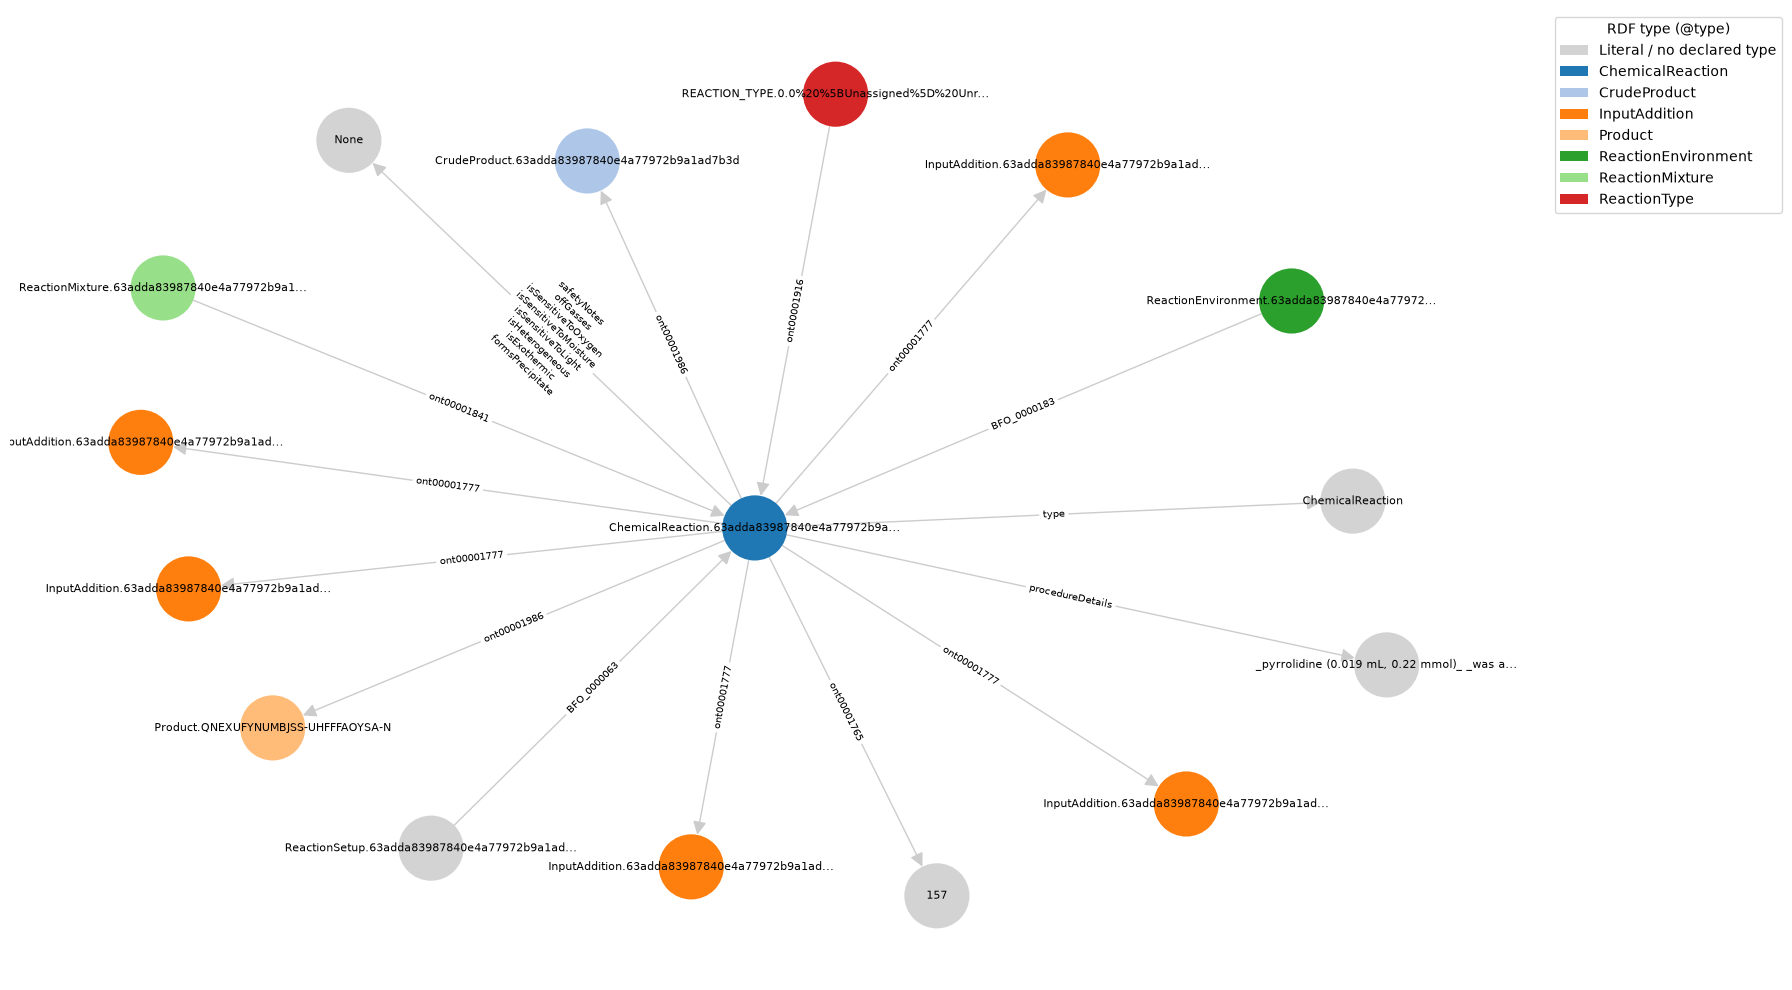

In [12]:
from collections import defaultdict
from matplotlib.patches import Patch

def short_label(term):
    text = term.value
    if text.startswith(("http://", "https://")):
        text = text.rstrip("/").rsplit("#", 1)[-1].rsplit("/", 1)[-1]
    return text if len(text) <= 45 else text[:42] + "..."

G = nx.DiGraph()

for row in store.query(connections_query):
    s, p, o = row["s"], row["p"], row["o"]
    source, target = str(s), str(o)

    G.add_node(source, label=short_label(s))
    G.add_node(target, label=short_label(o))

    label = short_label(p)
    if G.has_edge(source, target):
        G[source][target]["label"] += "\n" + label
    else:
        G.add_edge(source, target, label=label)

# Read types from the full store, including types not shown in this graph
types_by_node = defaultdict(set)
type_labels = {}

type_query = """
SELECT DISTINCT ?node ?type
WHERE {
    ?node a ?type .
}
"""

for row in store.query(type_query):
    node_id = str(row["node"])
    type_id = str(row["type"])

    types_by_node[node_id].add(type_id)
    type_labels[type_id] = short_label(row["type"])

# Group nodes by their type(s).
# Nodes with multiple types get a distinct combined category.
node_categories = {
    node: tuple(sorted(types_by_node.get(node, set())))
    for node in G.nodes
}

categories = sorted(set(node_categories.values()))
typed_categories = [category for category in categories if category]

cmap = plt.get_cmap("tab20")
category_colors = {
    category: cmap(index % cmap.N)
    for index, category in enumerate(typed_categories)
}

# Literal values and nodes without a declared type are gray
category_colors[()] = "lightgray"

colors = [
    category_colors[node_categories[node]]
    for node in G.nodes
]

positions = nx.spring_layout(G, seed=42, k=1.5)

fig, ax = plt.subplots(figsize=(18, 10))

nx.draw_networkx(
    G,
    positions,
    labels=nx.get_node_attributes(G, "label"),
    node_color=colors,
    node_size=2200,
    font_size=8,
    arrows=True,
    arrowsize=20,
    ax=ax,
    edge_color="#CCCCCC",
    font_color="#000000",
    linewidths=0,
)

nx.draw_networkx_edge_labels(
    G,
    positions,
    edge_labels=nx.get_edge_attributes(G, "label"),
    font_size=7,
    ax=ax,
)

# Explain the colors in a legend
legend_items = [
    Patch(
        facecolor=category_colors[category],
        label=(
            " + ".join(type_labels[type_id] for type_id in category)
            if category
            else "Literal / no declared type"
        ),
    )
    for category in categories
]

ax.legend(
    handles=legend_items,
    title="RDF type (@type)",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
)

ax.axis("off")
plt.tight_layout()
plt.show()